# Notebook 02 – Profiling Network Sites with K-Means
### Day 4 · Topic 2: K-Means Clustering

**Business use case: NetLink Ops site profiling**

NetLink Ops supports 300 customer sites. Today every site gets the same support contract, the same maintenance window and the same monitoring rules,
even though a small branch office and a data centre are completely different.

**The question:** *What natural groups of sites do we have?* There is **no label column**. Nobody has ever tagged the sites.
**The business decision:** design **4 support tiers**, each with its own maintenance window, spares policy and monitoring playbook.

| Column | Meaning |
|---|---|
| `device_count` | Number of network devices at the site |
| `avg_bandwidth_util_pct` | Average WAN link utilisation |
| `peak_traffic_gbps` | Peak traffic in the last 30 days |
| `alarms_30d` | Monitoring alarms raised in the last 30 days |
| `uptime_pct` | Site availability over the last 30 days |
| `avg_latency_ms` | Average latency to the core network |



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (8, 4.5)

## 2.1 Why Profile Sites? (Unsupervised Learning)

In [2]:
def make_sites(seed=42):
    """Synthetic NetLink Ops site data. Note: there is NO label column."""
    rng = np.random.default_rng(seed)
    # (hidden profile, count, device_count, bandwidth %, peak Gbps, alarms, uptime %, latency ms)
    recipes = [
        (135, (5, 30), (20, 40), (0.2, 2.0), (0, 6), (99.80, 99.98), (20, 40)),
        (75, (30, 80), (60, 80), (3, 12), (4, 15), (99.85, 99.99), (10, 20)),
        (60, (10, 60), (40, 60), (0.5, 5), (25, 60), (98.0, 99.3), (45, 90)),
        (30, (150, 500), (50, 70), (30, 120), (5, 20), (99.95, 100.0), (2, 8)),
    ]
    parts = []
    for n, dc, bw, pk, al, up, lat in recipes:
        parts.append(pd.DataFrame({
            "device_count": rng.integers(*dc, n),
            "avg_bandwidth_util_pct": rng.uniform(*bw, n).round(1),
            "peak_traffic_gbps": rng.uniform(*pk, n).round(1),
            "alarms_30d": rng.integers(*al, n),
            "uptime_pct": rng.uniform(*up, n).round(2),
            "avg_latency_ms": rng.uniform(*lat, n).round(1),
        }))
    sites = pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    sites.insert(0, "site_id", [f"SITE-{i:03d}" for i in range(1, len(sites) + 1)])
    return sites

sites = make_sites()
print(f"Sites: {len(sites)}")
sites.head()

Sites: 300


,site_id,device_count,avg_bandwidth_util_pct,peak_traffic_gbps,alarms_30d,uptime_pct,avg_latency_ms
0,SITE-001,73,78.4,9.6,7,99.93,16.6
1,SITE-002,32,49.2,1.5,54,98.51,64.1
2,SITE-003,52,66.3,4.3,9,99.87,17.9
3,SITE-004,7,33.2,0.6,1,99.81,28.7
4,SITE-005,40,56.8,1.3,53,98.81,45.2


In [3]:
sites.describe().round(1)

,device_count,avg_bandwidth_util_pct,peak_traffic_gbps,alarms_30d,uptime_pct,avg_latency_ms
count,300.0,300.0,300.0,300.0,300.0,300.0
mean,60.9,46.6,11.1,12.8,99.6,31.7
std,93.3,17.5,25.3,15.4,0.5,21.3
min,5.0,20.4,0.2,0.0,98.1,2.3
25%,18.0,30.4,1.1,3.0,99.8,16.4
50%,28.5,45.0,1.9,6.0,99.9,27.9
75%,53.0,62.0,6.7,14.0,100.0,38.1
max,479.0,79.7,117.8,57.0,100.0,89.2


**What to say:** "There's no 'answer' column here: no `tier`, no `label`. K-Means has to discover the groups on its own."

## 2.2 How K-Means Works: Assign → Update → Repeat
A small 2-feature demo first (alarms vs latency), written as a plain loop so you can *see* the two steps and the centroids moving.

Converged: nothing moved in round 8


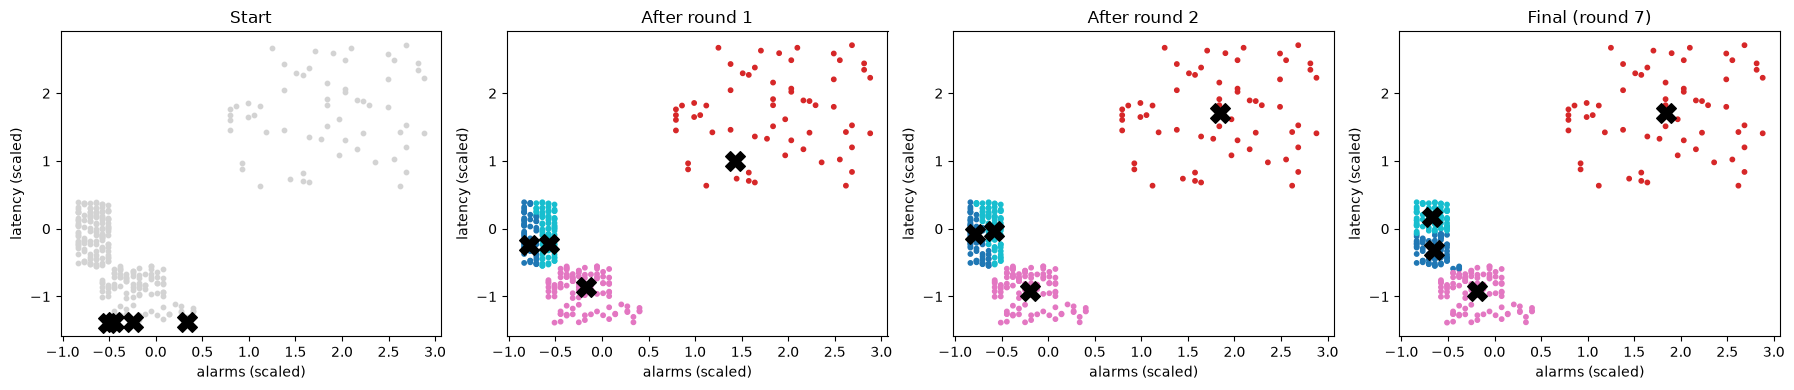

In [4]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

demo = StandardScaler().fit_transform(sites[["alarms_30d", "avg_latency_ms"]])

# Deliberately bad start: the 4 sites with the lowest latency (all along the bottom edge)
centroids = demo[np.argsort(demo[:, 1])[:4]].copy()
history = [centroids.copy()]

for round_no in range(1, 21):
    # ASSIGN: each site joins its nearest centroid
    distances = ((demo[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
    labels = distances.argmin(axis=1)
    # UPDATE: each centroid moves to the average of its sites
    new_centroids = np.array([demo[labels == k].mean(axis=0) for k in range(4)])
    if np.allclose(new_centroids, centroids):
        print(f"Converged: nothing moved in round {round_no}")
        break
    centroids = new_centroids
    history.append(centroids.copy())

def label_for(c):
    return (((demo[:, None, :] - c[None, :, :]) ** 2).sum(axis=2)).argmin(axis=1)

panels = [("Start", history[0]), ("After round 1", history[1]),
          ("After round 2", history[2]), (f"Final (round {len(history) - 1})", history[-1])]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, c) in zip(axes, panels):
    if title == "Start":
        ax.scatter(demo[:, 0], demo[:, 1], c="lightgrey", s=10)
    else:
        ax.scatter(demo[:, 0], demo[:, 1], c=label_for(c), cmap="tab10", s=10)
    ax.scatter(c[:, 0], c[:, 1], c="black", marker="X", s=200)
    ax.set_title(title); ax.set_xlabel("alarms (scaled)"); ax.set_ylabel("latency (scaled)")
plt.tight_layout(); plt.show()

**What to say:** "Black X = centroid. They all start along the bottom. In round 1, one centroid is dragged up towards the high-alarm, high-latency sites. Each round has the same two steps: assign, then update. When nothing moves any more, that's **convergence**. With only 2 features the bottom-left groups overlap; with all 6 features (next sections) they separate cleanly."

Note: scikit-learn's default start, **k-means++**, spreads the starting centroids out, and `n_init=10` runs the whole thing 10 times and keeps the best. We use both from here on, with a fixed `random_state` so results repeat.

## 2.3 Choosing Features and Scaling

In [5]:
features = ["device_count", "avg_bandwidth_util_pct", "peak_traffic_gbps",
            "alarms_30d", "uptime_pct", "avg_latency_ms"]

# How "spread out" each feature is in its raw units
sites[features].std().round(2).sort_values(ascending=False).to_frame("std_dev (raw units)")

,std_dev (raw units)
device_count,93.33
peak_traffic_gbps,25.31
avg_latency_ms,21.26
avg_bandwidth_util_pct,17.54
alarms_30d,15.36
uptime_pct,0.55


`device_count` varies by about 100, `uptime_pct` by about 0.5. Without scaling, a 1-device difference counts as much as a 1-percentage-point drop in uptime, so device count dominates.

In [6]:
# Unscaled vs scaled K-Means, both with K = 4
km_raw = KMeans(n_clusters=4, n_init=10, random_state=42).fit(sites[features])

scaler = StandardScaler()
X_sites = scaler.fit_transform(sites[features])
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_sites)

print("UNSCALED clusters: average profile")
print(sites.groupby(km_raw.labels_)[features].mean().round(1).assign(sites=pd.Series(km_raw.labels_).value_counts()))
print("\nSCALED clusters: average profile")
print(sites.groupby(kmeans.labels_)[features].mean().round(1).assign(sites=pd.Series(kmeans.labels_).value_counts()))

UNSCALED clusters: average profile
   device_count  avg_bandwidth_util_pct  peak_traffic_gbps  alarms_30d  uptime_pct  avg_latency_ms  sites
0          17.6                    29.7                1.1         2.6        99.9            30.7    135
1         383.6                    60.7               81.4        11.8       100.0             5.1     19
2          46.9                    60.6                5.4        23.2        99.3            38.6    135
3         206.8                    58.8               83.1        12.2       100.0             5.3     11

SCALED clusters: average profile
   device_count  avg_bandwidth_util_pct  peak_traffic_gbps  alarms_30d  uptime_pct  avg_latency_ms  sites
0          17.6                    29.7                1.1         2.6        99.9            30.7    135
1          37.6                    50.8                2.7        41.1        98.6            67.9     60
2         318.8                    60.0               82.0        11.9       100.0 

**What to say:** "Unscaled, K-Means wastes two clusters splitting the big sites into 'big' and 'very big', and throws busy hubs and unstable sites into one group, because it only really 'sees' device count. Scaled, every feature gets a fair vote and the groups make sense."

## 2.4 Choosing K by Business Need
The operations team can realistically run **4 support tiers** (staffing, spares, maintenance windows). So K = 4.

In [7]:
sites["cluster"] = kmeans.labels_
sites["cluster"].value_counts().sort_index().to_frame("number_of_sites")

,number_of_sites
cluster,
0,135
1,60
2,30
3,75


## 2.5 Interpreting, Naming and Using the Clusters

In [8]:
profile = sites.groupby("cluster")[features].mean().round(1)
profile["sites"] = sites["cluster"].value_counts().sort_index()
profile

,device_count,avg_bandwidth_util_pct,peak_traffic_gbps,alarms_30d,uptime_pct,avg_latency_ms,sites
cluster,,,,,,,
0,17.6,29.7,1.1,2.6,99.9,30.7,135
1,37.6,50.8,2.7,41.1,98.6,67.9,60
2,318.8,60.0,82.0,11.9,100.0,5.2,30
3,54.3,68.5,7.5,8.9,99.9,15.2,75


In [9]:
# Name each cluster from its profile (plain-English rules a manager can follow)
names = {}
remaining = list(profile.index)
core = profile.loc[remaining, "device_count"].idxmax(); names[core] = "Large core / data centre"; remaining.remove(core)
unstable = profile.loc[remaining, "alarms_30d"].idxmax(); names[unstable] = "Unstable, alarm-heavy site"; remaining.remove(unstable)
hub = profile.loc[remaining, "avg_bandwidth_util_pct"].idxmax(); names[hub] = "Busy regional hub"; remaining.remove(hub)
names[remaining[0]] = "Small quiet branch"

sites["profile"] = sites["cluster"].map(names)
profile.index = profile.index.map(names)
profile

,device_count,avg_bandwidth_util_pct,peak_traffic_gbps,alarms_30d,uptime_pct,avg_latency_ms,sites
cluster,,,,,,,
Small quiet branch,17.6,29.7,1.1,2.6,99.9,30.7,135
"Unstable, alarm-heavy site",37.6,50.8,2.7,41.1,98.6,67.9,60
Large core / data centre,318.8,60.0,82.0,11.9,100.0,5.2,30
Busy regional hub,54.3,68.5,7.5,8.9,99.9,15.2,75


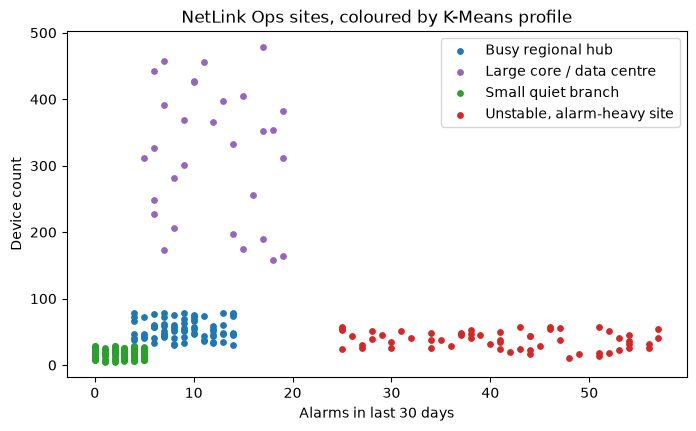

In [10]:
colors = {"Small quiet branch": "tab:green", "Busy regional hub": "tab:blue",
          "Unstable, alarm-heavy site": "tab:red", "Large core / data centre": "tab:purple"}
for name, grp in sites.groupby("profile"):
    plt.scatter(grp["alarms_30d"], grp["device_count"], s=15, label=name, c=colors[name])
plt.xlabel("Alarms in last 30 days"); plt.ylabel("Device count")
plt.title("NetLink Ops sites, coloured by K-Means profile")
plt.legend(); plt.show()

In [11]:
# Turn profiles into action: one playbook per tier
playbook = pd.DataFrame({
    "profile": ["Large core / data centre", "Busy regional hub", "Unstable, alarm-heavy site", "Small quiet branch"],
    "support_tier": ["Platinum", "Gold", "Watch-list", "Standard"],
    "maintenance_window": ["Quarterly, change board", "Monthly, night", "Weekly review", "Quarterly, any time"],
    "spares": ["On-site", "4-hour depot", "Next-day + root-cause review", "Next-business-day"],
})
playbook.merge(sites["profile"].value_counts().rename("sites"), left_on="profile", right_index=True)

,profile,support_tier,maintenance_window,spares,sites
0,Large core / data centre,Platinum,"Quarterly, change board",On-site,30
1,Busy regional hub,Gold,"Monthly, night",4-hour depot,75
2,"Unstable, alarm-heavy site",Watch-list,Weekly review,Next-day + root-cause review,60
3,Small quiet branch,Standard,"Quarterly, any time",Next-business-day,135


In [12]:
# A brand-new site comes online: which tier does it belong to?
new_site = pd.DataFrame([{"device_count": 45, "avg_bandwidth_util_pct": 72, "peak_traffic_gbps": 8.5,
                          "alarms_30d": 9, "uptime_pct": 99.95, "avg_latency_ms": 14}])
cluster_id = kmeans.predict(scaler.transform(new_site[features]))[0]
print(f"New site -> {names[cluster_id]}")

New site -> Busy regional hub


**What to say:** "K-Means did the grouping. *We* did the naming and the playbooks. That second part is where the business value is."